# Step 2: Hormuz state coding (0 to 4), event study, merge into the panel
Run Step 1 first so `monthly_panel.csv` exists in your `Dataset` folder.

In [ ]:
!pip install -q xlrd
import pandas as pd, numpy as np
from google.colab import drive
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/My Work/Research/AI+ BBA/Supply Chain_GNN/Dataset'

Mounted at /content/drive


## 1. Load Daily Transits ----------

In [ ]:
tr = pd.read_csv(f"{BASE}/1. IMF Hormuz/straits-transits.csv", parse_dates=["date"]).set_index("date")
daily = tr[["n_total"]].copy()

## 2. Baseline And Throughput Ratio ----------

In [ ]:
# Baseline = median daily transits in the calm window before the break (edit the window if you change your definition)
BASE_START, BASE_END = "2025-03-01", "2026-02-15"
baseline = daily.loc[BASE_START:BASE_END, "n_total"].median()
daily["ma7"] = daily["n_total"].rolling(7, min_periods=4).mean()
daily["ratio"] = daily["ma7"] / baseline
print("baseline (median daily transits):", baseline)

baseline (median daily transits): 85.0


## 3. STATE CODING (0-4, as defined in your proposal) ----------

In [ ]:
# raw state from throughput:   ratio >= 0.5 -> 0 | 0.2-0.5 -> 2 | < 0.2 -> 3
raw = np.where(daily["ratio"] >= 0.5, 0, np.where(daily["ratio"] >= 0.2, 2, 3))
raw = pd.Series(raw, index=daily.index).where(daily["ratio"].notna())

# persistence rule: worsening is accepted after 2 days in a row (fast warning),
# improving only after 5 days in a row (avoids false "recovery")
def smooth(s, k_worse=2, k_better=5):
    out, cur, run_val, run_len = [], None, None, 0
    for v in s:
        if pd.isna(v): out.append(np.nan); continue
        if cur is None: cur = v
        if v == run_val: run_len += 1
        else: run_val, run_len = v, 1
        need = k_worse if v > cur else k_better
        if v != cur and run_len >= need: cur = v
        out.append(cur)
    return pd.Series(out, index=s.index)
daily["state"] = smooth(raw)

# state 4 (reopening / recovery): throughput is back above 0.2 within 60 days after a state-3 spell
was3 = (daily["state"] == 3).astype(float).rolling(60, min_periods=1).max().shift(1).fillna(0) > 0
daily.loc[daily["state"].isin([0, 2]) & was3, "state"] = 4

# state 1 (elevated security concern) cannot be read from transit counts.
# Fill it by hand from JMIC / IMO advisories: {"start": "end"} date ranges, only where state is 0.
MANUAL_STATE1 = {}   # example: {"2026-02-20": "2026-02-27"}
for a, b in MANUAL_STATE1.items():
    m = (daily.index >= a) & (daily.index <= b) & (daily["state"] == 0)
    daily.loc[m, "state"] = 1

# AIS reliability flag: your proposal (EIA) says AIS became unreliable after Feb 2026
daily["ais_unreliable"] = (daily.index >= "2026-03-01").astype(int)
daily["state"] = daily["state"].astype("Int64")
print(daily["state"].value_counts(dropna=False).sort_index())
print(daily.loc["2026-02-24":"2026-03-10", ["n_total", "ratio", "state"]].round(2))

state
0       367
2         2
3       212
4        14
<NA>      3
Name: count, dtype: Int64
            n_total  ratio  state
date                             
2026-02-24       93   1.22      0
2026-02-25      116   1.24      0
2026-02-26       89   1.19      0
2026-02-27       64   1.14      0
2026-02-28       57   1.09      0
2026-03-01       20   0.91      0
2026-03-02        4   0.74      0
2026-03-03        4   0.59      0
2026-03-04        0   0.40      0
2026-03-05        3   0.26      2
2026-03-06        2   0.15      2
2026-03-07        3   0.06      3
2026-03-08        2   0.03      3
2026-03-09        2   0.03      3
2026-03-10        2   0.02      3


## 4. Monthly Hormuz Variables ----------

In [ ]:
daily["month"] = daily.index.to_period("M")
hz = daily.groupby("month").agg(
    hz_transits=("n_total", "mean"),
    hz_ratio=("ratio", "mean"),
    hz_state_mode=("state", lambda s: s.dropna().astype(int).mode().iloc[0] if s.notna().any() else np.nan),
    hz_share_state3=("state", lambda s: (s == 3).mean()),
    hz_share_state4=("state", lambda s: (s == 4).mean()),
    ais_unreliable=("ais_unreliable", "max")).reset_index()
hz["hz_state_mode"] = hz["hz_state_mode"].astype(float)
print(hz.assign(month=hz["month"].astype(str)).round(2).to_string(index=False))

  month  hz_transits  hz_ratio  hz_state_mode hz_share_state3 hz_share_state4  ais_unreliable
2025-02        60.00       NaN            NaN            <NA>            <NA>               0
2025-03        83.77      0.96            0.0             0.0             0.0               0
2025-04       102.37      1.20            0.0             0.0             0.0               0
2025-05       102.97      1.22            0.0             0.0             0.0               0
2025-06       102.23      1.20            0.0             0.0             0.0               0
2025-07        95.23      1.12            0.0             0.0             0.0               0
2025-08        94.52      1.11            0.0             0.0             0.0               0
2025-09        87.93      1.03            0.0             0.0             0.0               0
2025-10        89.42      1.06            0.0             0.0             0.0               0
2025-11        67.37      0.84            0.0             0.

## 5. Event Study Around The Break ----------

In [ ]:
panel = pd.read_csv(f"{BASE}/monthly_panel.csv")          # saved by Step 1
panel["month"] = pd.PeriodIndex(panel["month"], freq="M")
onset = pd.Period("2026-03", freq="M")
panel["rel_month"] = (panel["month"] - onset).apply(lambda x: x.n)
ev = panel[(panel.rel_month >= -6) & (panel.rel_month <= 6)][["month", "rel_month", "brent", "gscpi", "oni"]]
ev = ev.merge(hz[["month", "hz_transits", "hz_state_mode"]], on="month", how="left")
ref = ev.loc[ev.rel_month == -1]
ev["brent_vs_feb"] = (ev["brent"] / float(ref["brent"].iloc[0]) - 1).round(3)
ev["gscpi_vs_feb"] = (ev["gscpi"] - float(ref["gscpi"].iloc[0])).round(2)
print(ev.assign(month=ev["month"].astype(str)).round(2).to_string(index=False))

  month  rel_month  brent  gscpi   oni  hz_transits  hz_state_mode  brent_vs_feb  gscpi_vs_feb
2025-09         -6  67.99  -0.04 -0.40        87.93            0.0         -0.04         -0.53
2025-10         -5  64.54  -0.15 -0.51        89.42            0.0         -0.09         -0.64
2025-11         -4  63.80  -0.21 -0.55        67.37            0.0         -0.10         -0.70
2025-12         -3  62.54   0.47 -0.54        55.55            0.0         -0.12         -0.02
2026-01         -2  66.60   0.36 -0.37        58.45            0.0         -0.06         -0.13
2026-02         -1  70.89   0.49 -0.14        78.29            0.0          0.00          0.00
2026-03          0 103.13   0.63  0.13         3.19            3.0          0.46          0.14
2026-04          1 117.29   1.78  0.48         7.13            3.0          0.66          1.29
2026-05          2 107.14   1.81   NaN         3.94            3.0          0.51          1.32
2026-06          3  85.40   1.21   NaN        12.9

## 6. Merge Into The Panel And Save ----------

In [ ]:
panel2 = panel.drop(columns=[c for c in panel.columns if c.startswith("hz_")], errors="ignore").merge(hz, on="month", how="left")
panel2.to_csv(f"{BASE}/monthly_panel_with_hormuz_state.csv", index=False)
daily.drop(columns=["month"]).to_csv(f"{BASE}/hormuz_daily_state.csv")

## 7. Figure ----------

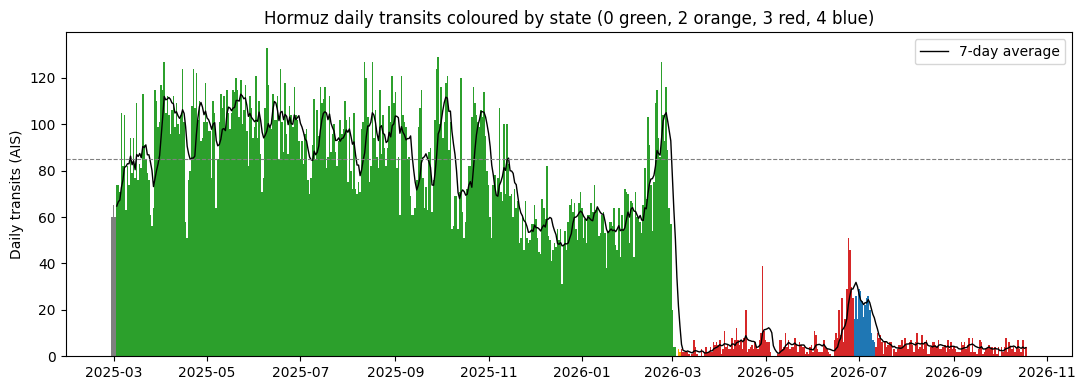

In [ ]:
import matplotlib.pyplot as plt
colors = {0: "tab:green", 1: "gold", 2: "orange", 3: "tab:red", 4: "tab:blue"}
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(daily.index, daily["n_total"], color=[colors.get(int(s), "grey") if pd.notna(s) else "grey" for s in daily["state"]], width=1.0)
ax.plot(daily.index, daily["ma7"], color="black", lw=1, label="7-day average")
ax.axhline(baseline, color="grey", ls="--", lw=0.8)
ax.set_ylabel("Daily transits (AIS)"); ax.set_title("Hormuz daily transits coloured by state (0 green, 2 orange, 3 red, 4 blue)")
ax.legend(); fig.tight_layout(); fig.savefig(f"{BASE}/hormuz_state_chart.png", dpi=150)